# Kaggle Dataset Analysis

In [ ]:
# Run this if you need to download the data
%pip install kagglehub

In [ ]:
# Data can be loaded through kagglehub api
import kagglehub

major_minor_triad_dataset = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
major_minor_guitar_piano_dataset = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

In [7]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from pathlib import Path
import pandas as pd

### Look up the data

In [8]:
DATA_DIR = Path('../data/Audio_Files')

major_files = sorted(list((DATA_DIR / 'Major').glob('*.wav')))
minor_files = sorted(list((DATA_DIR / 'Minor').glob('*.wav')))

     count      mean       std   min  25%   50%       75%       max
maj  502.0  2.238542  0.036334  2.20  2.2  2.25  2.250000  2.299977
min  357.0  2.239490  0.041660  2.15  2.2  2.25  2.299977  2.299977


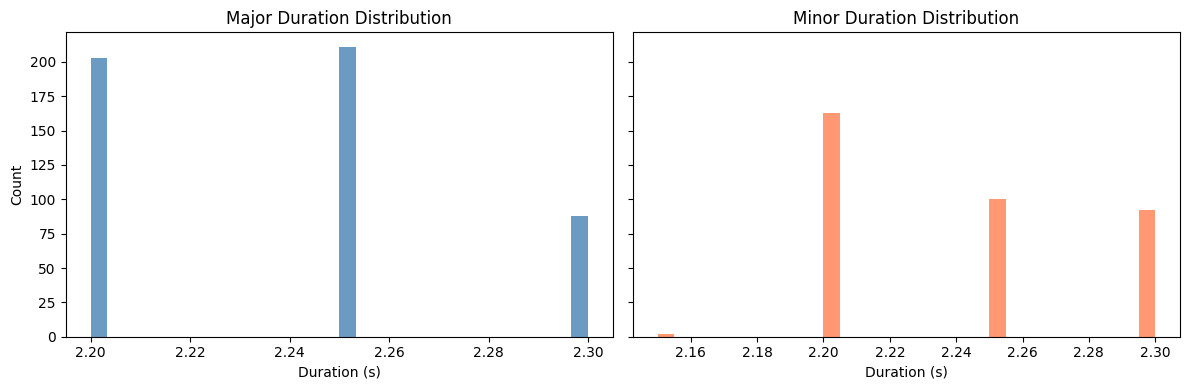

In [4]:
def durations_for_files(files):
    durations = []
    for f in files:
        y, sr = librosa.load(str(f), sr=None)
        durations.append(librosa.get_duration(y=y, sr=sr))
    return np.array(durations)

major_durations = durations_for_files(major_files)
minor_durations = durations_for_files(minor_files)

report = pd.DataFrame({
    'maj': pd.Series(major_durations),
    'min': pd.Series(minor_durations)
})

print(report.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(major_durations, bins=30, alpha=0.8, color='steelblue')
axes[0].set_title('Major Duration Distribution')
axes[0].set_xlabel('Duration (s)')
axes[0].set_ylabel('Count')

axes[1].hist(minor_durations, bins=30, alpha=0.8, color='coral')
axes[1].set_title('Minor Duration Distribution')
axes[1].set_xlabel('Duration (s)')

plt.tight_layout()
plt.show()

In [ ]:
def get_sample_rates(files):
    rates = []
    for f in files:
        rates.append(librosa.get_samplerate(str(f)))
    return np.array(rates)

major_sample_rates = get_sample_rates(major_files)
minor_sample_rates = get_sample_rates(minor_files)

sr_counts = pd.DataFrame({
    'Major': pd.Series(major_sample_rates).value_counts(),
    'Minor': pd.Series(minor_sample_rates).value_counts()
}).fillna(0).astype(int)

print("Sample Rate Counts (Hz):")
print(sr_counts)

Sample Rate Counts (Hz):
       Major  Minor
44100    502    357


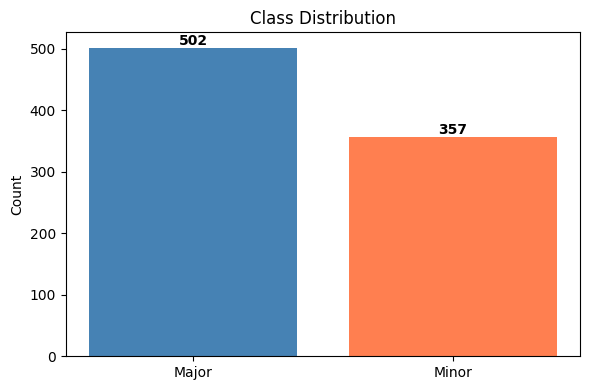

In [3]:
labels = ['Major'] * len(major_files) + ['Minor'] * len(minor_files)

fig, ax = plt.subplots(figsize=(6, 4))
unique, counts = np.unique(labels, return_counts=True)
ax.bar(unique, counts, color=['steelblue', 'coral'])
for i, (u, c) in enumerate(zip(unique, counts)):
    ax.text(i, c + 5, str(c), ha='center', fontweight='bold')
ax.set_ylabel('Count')
ax.set_title('Class Distribution')
plt.tight_layout()
plt.show()

Data distribution shows a heavier major class. That might lead to a bias inside the model and recognise more chords as major than minor.

### See first how the waveform differs between a major and minor chord
The dataset should be organized so that every index of the major chord corresponds to the same index of the minor chord. This way we can easily compare the two chords and see how they differ in the waveform. We are reducing the sample rate here, so the peaks in the waveform can be seen more clearly.

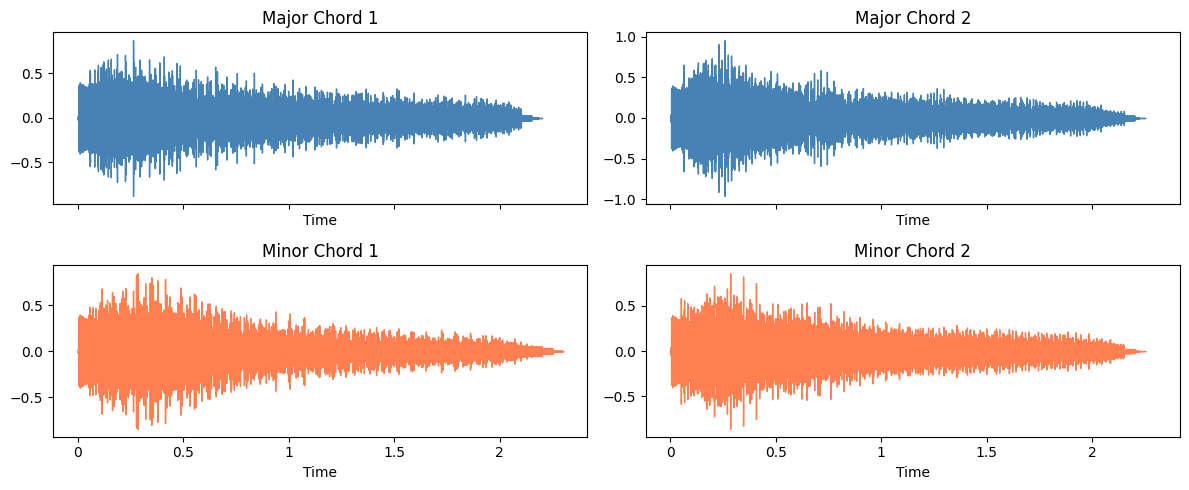

In [9]:
y_maj, sr = librosa.load(str(major_files[2]), sr=22050)
y_min, _ = librosa.load(str(minor_files[2]), sr=22050)
y_maj2, _ = librosa.load(str(major_files[0]), sr=22050)
y_min2, _ = librosa.load(str(minor_files[0]), sr=22050)

fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=True)
librosa.display.waveshow(y_maj, sr=sr, ax=axes[0][0], color='steelblue')
axes[0][0].set_title('Major Chord 1')
librosa.display.waveshow(y_min, sr=sr, ax=axes[1][0], color='coral')
axes[1][0].set_title('Minor Chord 1')
librosa.display.waveshow(y_maj2, sr=sr, ax=axes[0][1], color='steelblue')
axes[0][1].set_title('Major Chord 2')
librosa.display.waveshow(y_min2, sr=sr, ax=axes[1][1], color='coral')
axes[1][1].set_title('Minor Chord 2')
plt.tight_layout()
plt.show()

The diffrence between the two waveforms is not very clear, but we can see that the major chord has a higher amplitude than the minor chord.

### Next we will see how the two chords differ in a Mel spectrogram

Because the data consists of triads, we can expect that the flat third in the minor will have a lower frequency, so we must see a shift in the spectrogram.

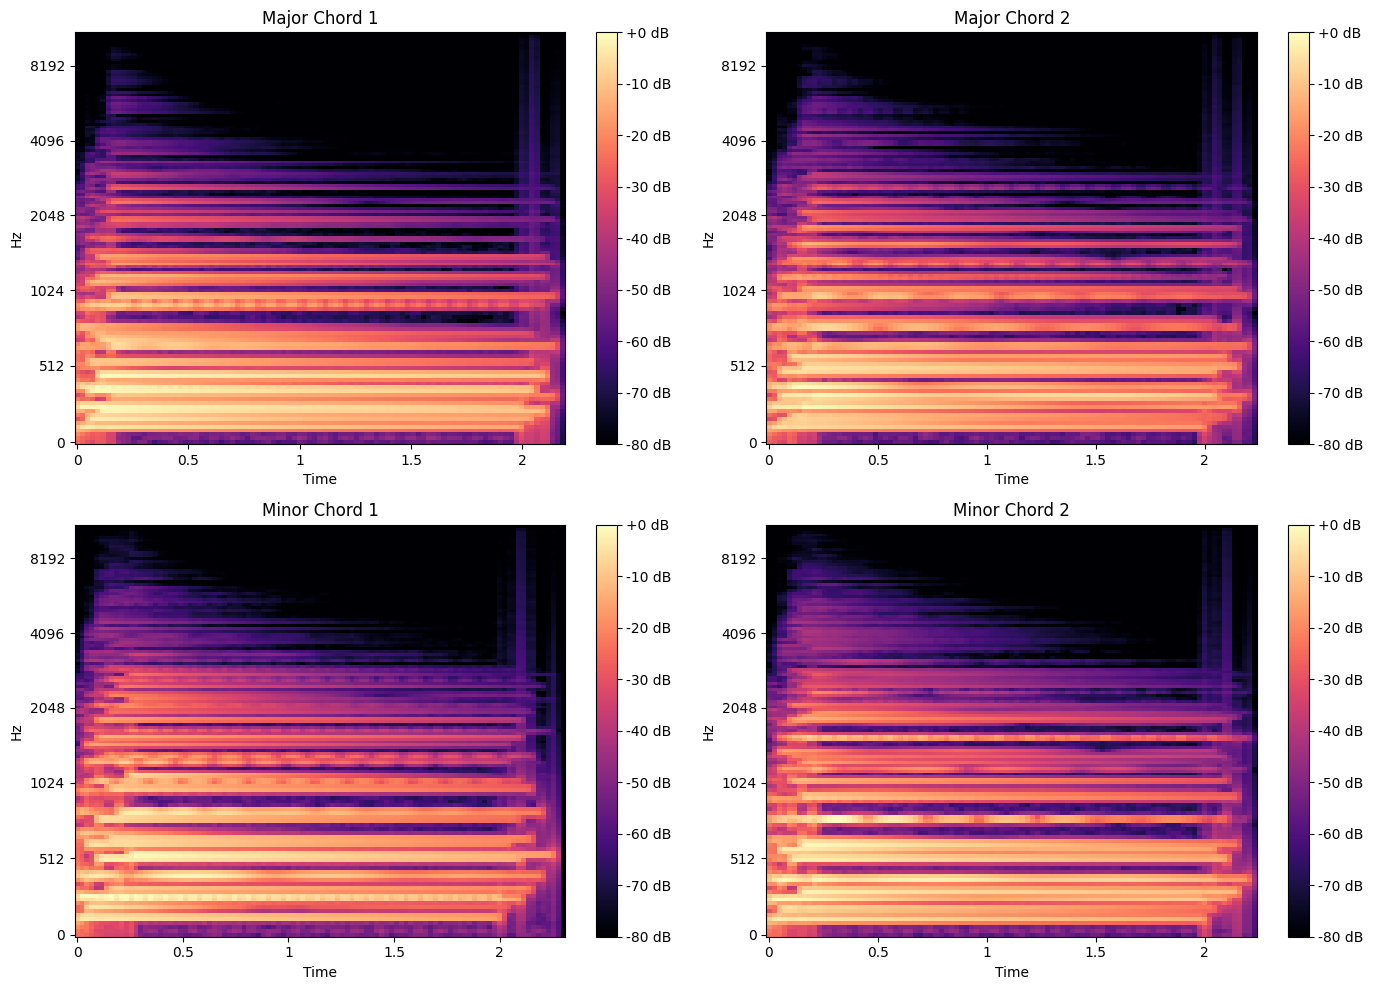

In [14]:
mel_maj = librosa.feature.melspectrogram(y=y_maj, sr=sr, n_mels=128)
mel_min = librosa.feature.melspectrogram(y=y_min, sr=sr, n_mels=128)
mel_maj_db = librosa.power_to_db(mel_maj, ref=np.max)
mel_min_db = librosa.power_to_db(mel_min, ref=np.max)

mel_maj2 = librosa.feature.melspectrogram(y=y_maj2, sr=sr, n_mels=128)
mel_min2 = librosa.feature.melspectrogram(y=y_min2, sr=sr, n_mels=128)
mel_maj_db2 = librosa.power_to_db(mel_maj2, ref=np.max)
mel_min_db2 = librosa.power_to_db(mel_min2, ref=np.max)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
img0 = librosa.display.specshow(mel_maj_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[0][0])
axes[0][0].set_title('Major Chord 1')
fig.colorbar(img0, ax=axes[0][0], format='%+2.0f dB')

img1 = librosa.display.specshow(mel_min_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[1][0])
axes[1][0].set_title('Minor Chord 1')
fig.colorbar(img1, ax=axes[1][0], format='%+2.0f dB')

img2 = librosa.display.specshow(mel_maj_db2, sr=sr, x_axis='time', y_axis='mel', ax=axes[0][1])
axes[0][1].set_title('Major Chord 2')
fig.colorbar(img2, ax=axes[0][1], format='%+2.0f dB')

img3 = librosa.display.specshow(mel_min_db2, sr=sr, x_axis='time', y_axis='mel', ax=axes[1][1])
axes[1][1].set_title('Minor Chord 2')
fig.colorbar(img3, ax=axes[1][1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

For the first minor chord, the shift is very clear in the 1024 Hz bin. Interestingly enough we observe a longer sustain in the minor chord's lower registers, which might also contribute to the differentiating of the two chords. Of course we cant draw conclusions from two examples, but this is a good sign that the two chords are different enough to be classified by a model.

### Chromagram
We can see more clearly this shift in the chromagram, which shows the presence of all the 12 main semitones.

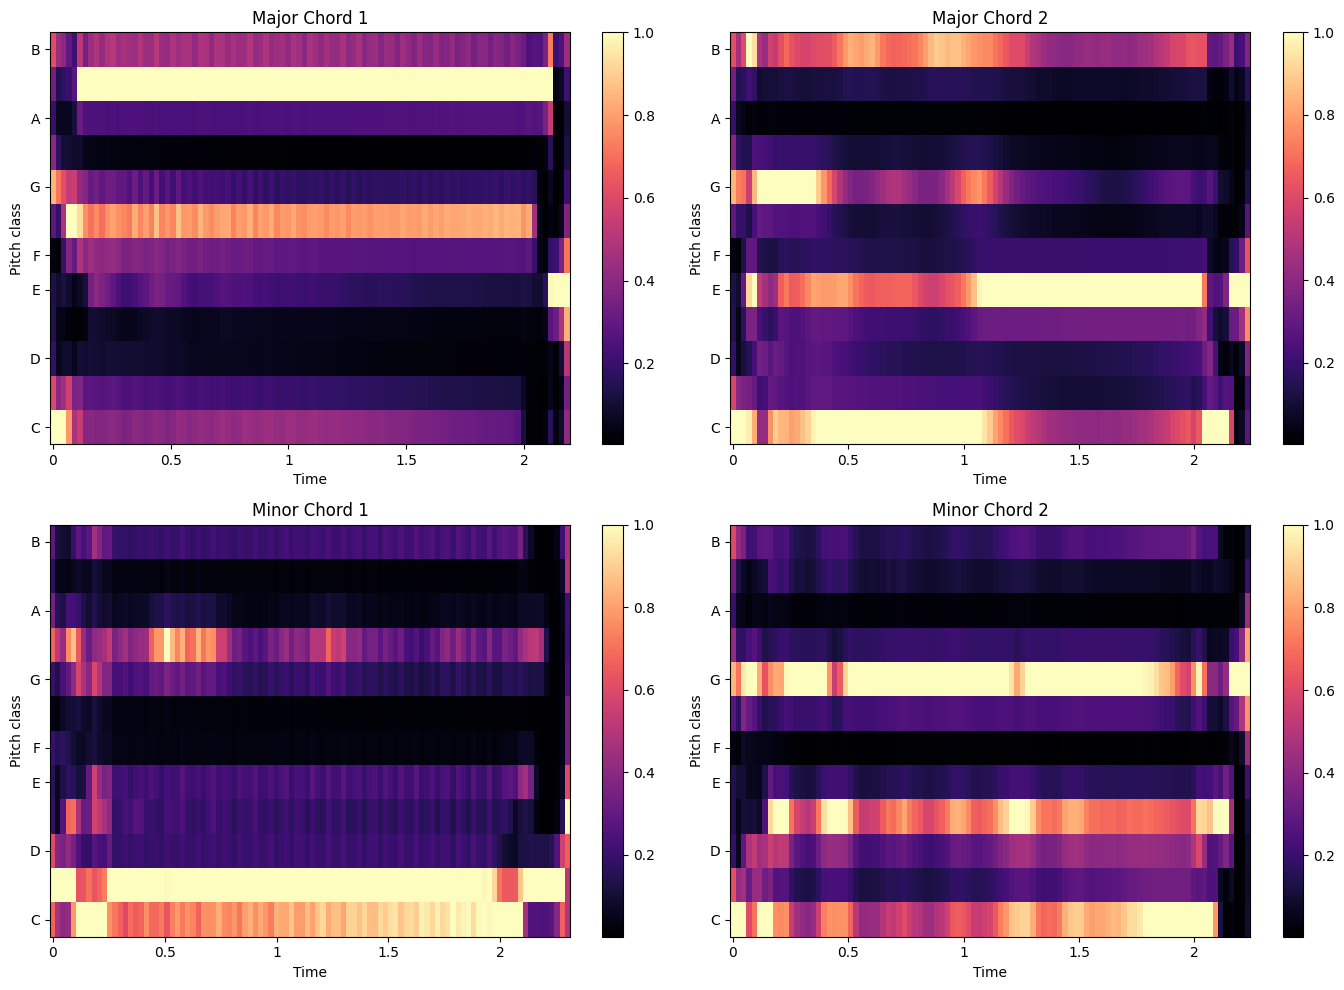

In [12]:
chroma_maj = librosa.feature.chroma_stft(y=y_maj, sr=sr)
chroma_min = librosa.feature.chroma_stft(y=y_min, sr=sr)
chroma_maj2 = librosa.feature.chroma_stft(y=y_maj2, sr=sr)
chroma_min2 = librosa.feature.chroma_stft(y=y_min2, sr=sr)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
img0 = librosa.display.specshow(chroma_maj, sr=sr, x_axis='time', y_axis='chroma', ax=axes[0][0])
axes[0][0].set_title('Major Chord 1')
fig.colorbar(img0, ax=axes[0][0])

img1 = librosa.display.specshow(chroma_min, sr=sr, x_axis='time', y_axis='chroma', ax=axes[1][0])
axes[1][0].set_title('Minor Chord 1')
fig.colorbar(img1, ax=axes[1][0])

img2 = librosa.display.specshow(chroma_maj2, sr=sr, x_axis='time', y_axis='chroma', ax=axes[0][1])
axes[0][1].set_title('Major Chord 2')
fig.colorbar(img2, ax=axes[0][1])

img3 = librosa.display.specshow(chroma_min2, sr=sr, x_axis='time', y_axis='chroma', ax=axes[1][1])
axes[1][1].set_title('Minor Chord 2')
fig.colorbar(img3, ax=axes[1][1])
plt.tight_layout()
plt.show()

Here we can even distinguish what the chord might be - the second column we see the major chord has presense in C, E, G, while the minor chord has presense in C, Eb, G. We observe a big amount of noise in the chromagram, because there are more than 3 semitones present in bright colors. If we try to infer the chord from the chromagram, we might be misled by the noise, caused by harmonic obertones.

### MFCCs
MFCCs are a more compact representation of the spectrogram, and they are often used in audio classification tasks. We will see how it represents the four examples of major and minor chords.

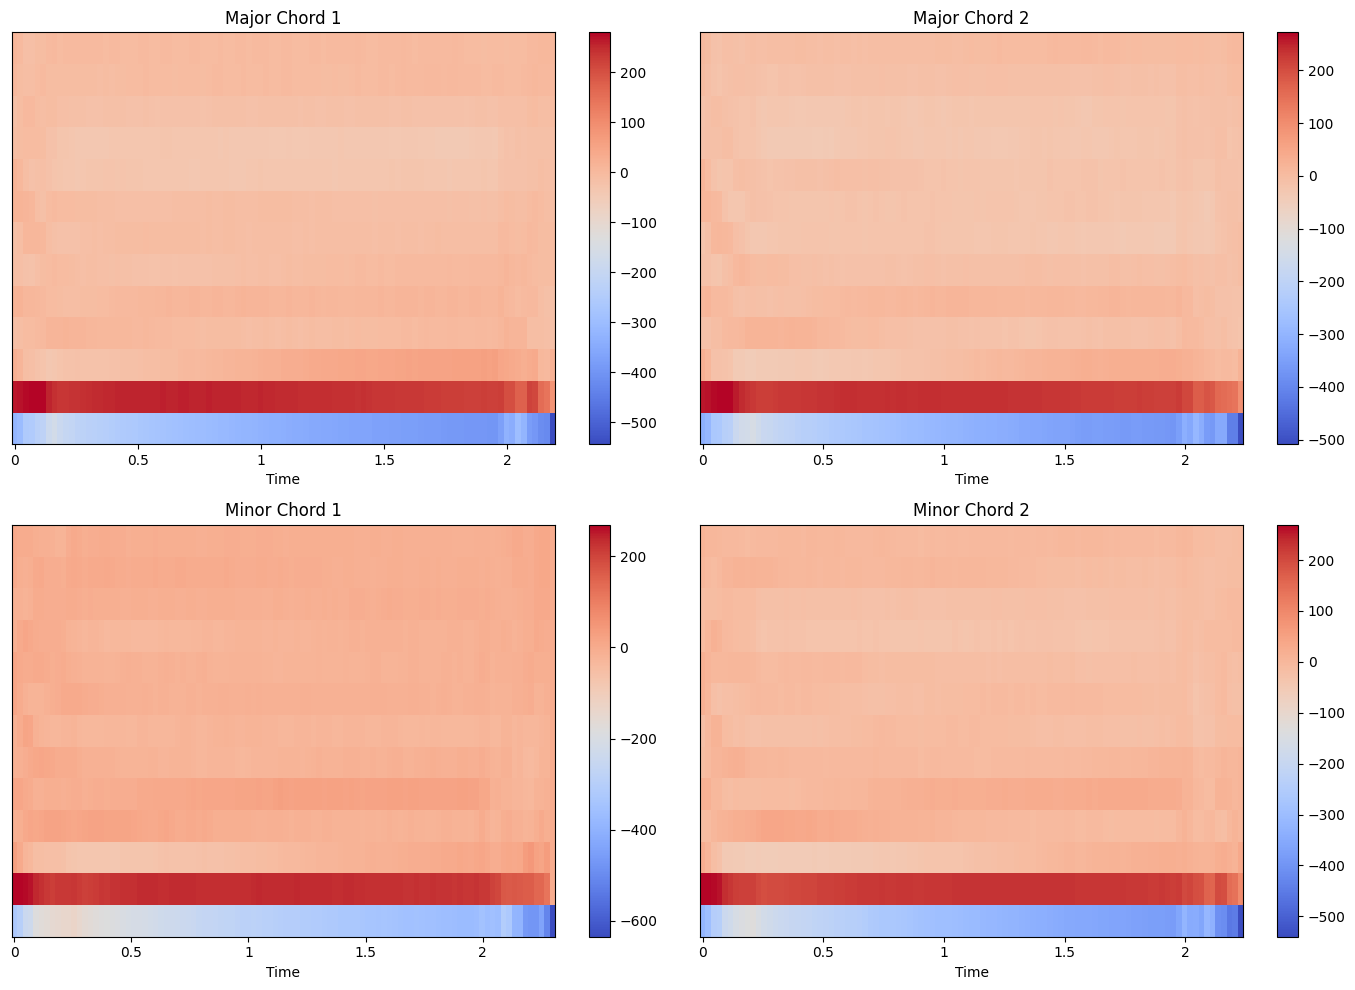

In [ ]:
mfcc_maj = librosa.feature.mfcc(y=y_maj, sr=sr, n_mfcc=13)
mfcc_min = librosa.feature.mfcc(y=y_min, sr=sr, n_mfcc=13)
mfcc_maj2 = librosa.feature.mfcc(y=y_maj2, sr=sr, n_mfcc=13)
mfcc_min2 = librosa.feature.mfcc(y=y_min2, sr=sr, n_mfcc=13)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

img0 = librosa.display.specshow(mfcc_maj, sr=sr, x_axis='time', ax=axes[0][0])
axes[0][0].set_title('Major Chord 1')
fig.colorbar(img0, ax=axes[0][0])

img1 = librosa.display.specshow(mfcc_maj2, sr=sr, x_axis='time', ax=axes[0][1])
axes[0][1].set_title('Major Chord 2')
fig.colorbar(img1, ax=axes[0][1])

img2 = librosa.display.specshow(mfcc_min, sr=sr, x_axis='time', ax=axes[1][0])
axes[1][0].set_title('Minor Chord 1')
fig.colorbar(img2, ax=axes[1][0])

img3 = librosa.display.specshow(mfcc_min2, sr=sr, x_axis='time', ax=axes[1][1])
axes[1][1].set_title('Minor Chord 2')
fig.colorbar(img3, ax=axes[1][1])

plt.tight_layout()
plt.show()

These seem to show differences that an algorithm might be able to learn, but are not very visible to the naked eye in this form.

### Mean Chroma Profile
We can next look for peaks in the mean chroma profile that can better distinguish the two chords. Still, trying to classify a chord by its 3 chords is too naive of a solution, because of the noise.

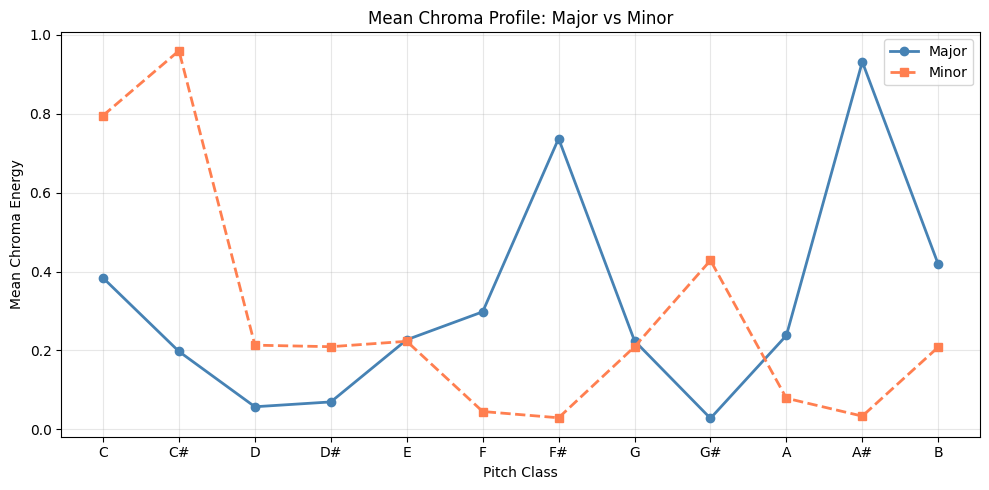

In [13]:
pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pitch_classes, np.mean(chroma_maj, axis=1), 'o-', color='steelblue', linewidth=2, label='Major')
ax.plot(pitch_classes, np.mean(chroma_min, axis=1), 's--', color='coral', linewidth=2, label='Minor')
ax.set_xlabel('Pitch Class')
ax.set_ylabel('Mean Chroma Energy')
ax.set_title('Mean Chroma Profile: Major vs Minor')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

We can see clear peaks here for two semitones, with the third noote being less clear. Still it is a good visual representation of the chroma energy distribution inside the images we will be classifying.

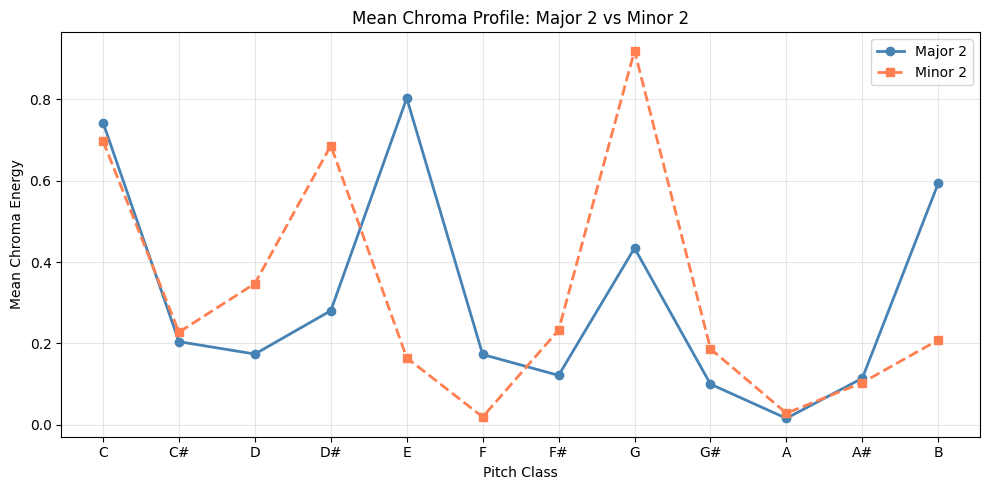

In [11]:
pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pitch_classes, np.mean(chroma_maj2, axis=1), 'o-', color='steelblue', linewidth=2, label='Major 2')
ax.plot(pitch_classes, np.mean(chroma_min2, axis=1), 's--', color='coral', linewidth=2, label='Minor 2')
ax.set_xlabel('Pitch Class')
ax.set_ylabel('Mean Chroma Energy')
ax.set_title('Mean Chroma Profile: Major 2 vs Minor 2')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Here we can see peaks more clearly, but there are 4 peaks for the major chord and 3 for the minor. We can not be sure wheter one of this comes from noise or the chord itself is played with 4 notes.

### Full Dataset Statistics

In [19]:
from src.features import extract_chroma, extract_mfcc

all_chroma_maj = []
all_chroma_min = []
all_mfcc_maj = []
all_mfcc_min = []
durations_maj = []
durations_min = []
rms_maj = []
rms_min = []

for f in major_files:
    y_tmp, sr_tmp = librosa.load(str(f), sr=22050)
    durations_maj.append(len(y_tmp) / sr_tmp)
    rms_maj.append(np.sqrt(np.mean(y_tmp**2)))
    all_chroma_maj.append(extract_chroma(y_tmp, sr_tmp))
    all_mfcc_maj.append(extract_mfcc(y_tmp, sr_tmp))

for f in minor_files:
    y_tmp, sr_tmp = librosa.load(str(f), sr=22050)
    durations_min.append(len(y_tmp) / sr_tmp)
    rms_min.append(np.sqrt(np.mean(y_tmp**2)))
    all_chroma_min.append(extract_chroma(y_tmp, sr_tmp))
    all_mfcc_min.append(extract_mfcc(y_tmp, sr_tmp))

all_chroma_maj = np.array(all_chroma_maj)
all_chroma_min = np.array(all_chroma_min)
all_mfcc_maj = np.array(all_mfcc_maj)
all_mfcc_min = np.array(all_mfcc_min)

In [23]:
import pandas as pd

stats = {
    'Metric': ['Count', 'Duration (mean)', 'Duration (std)', 'RMS (mean)', 'RMS (std)',
               'Chroma mean (mean)', 'Chroma mean (std)', 'MFCC mean (mean)', 'MFCC mean (std)'],
    'Major': [
        len(major_files),
        f'{np.mean(durations_maj):.3f}s',
        f'{np.std(durations_maj):.4f}s',
        f'{np.mean(rms_maj):.4f}',
        f'{np.std(rms_maj):.4f}',
        f'{np.mean(all_chroma_maj):.4f}',
        f'{np.std(all_chroma_maj):.4f}',
        f'{np.mean(all_mfcc_maj):.2f}',
        f'{np.std(all_mfcc_maj):.2f}',
    ],
    'Minor': [
        len(minor_files),
        f'{np.mean(durations_min):.3f}s',
        f'{np.std(durations_min):.4f}s',
        f'{np.mean(rms_min):.4f}',
        f'{np.std(rms_min):.4f}',
        f'{np.mean(all_chroma_min):.4f}',
        f'{np.std(all_chroma_min):.4f}',
        f'{np.mean(all_mfcc_min):.2f}',
        f'{np.std(all_mfcc_min):.2f}',
    ],
}

df_stats = pd.DataFrame(stats).T
df_stats

,0,1,2,3,4,5,6,7,8
Metric,Count,Duration (mean),Duration (std),RMS (mean),RMS (std),Chroma mean (mean),Chroma mean (std),MFCC mean (mean),MFCC mean (std)
Major,502,2.239s,0.0363s,0.1346,0.0228,0.3135,0.2210,-14.39,108.69
Minor,357,2.240s,0.0416s,0.1341,0.0230,0.3058,0.2239,-14.57,108.90


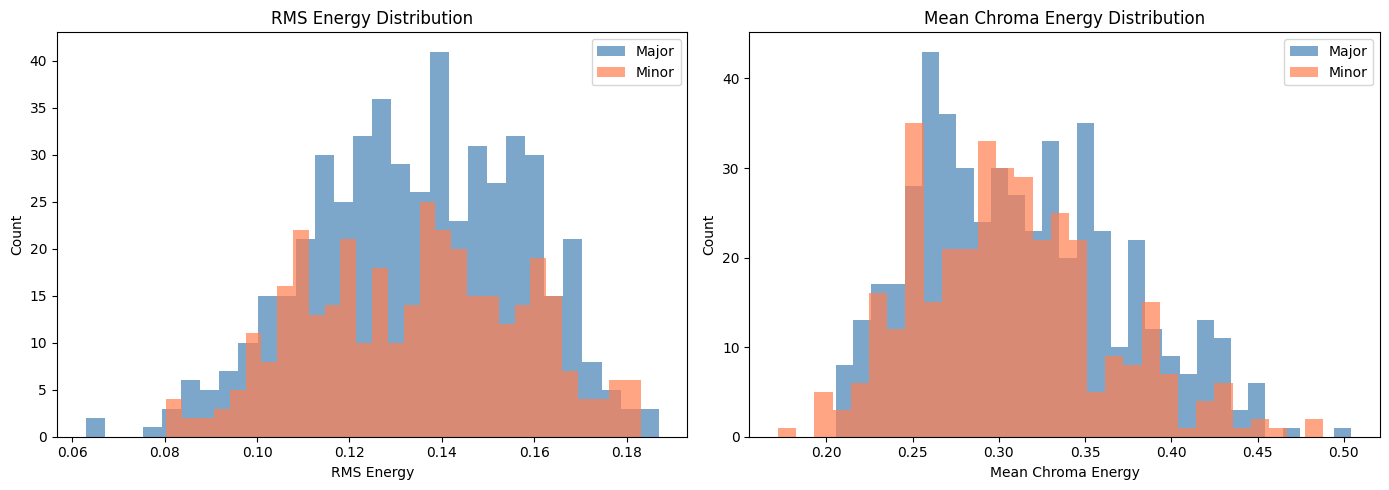

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(rms_maj, bins=30, alpha=0.7, color='steelblue', label='Major')
axes[0].hist(rms_min, bins=30, alpha=0.7, color='coral', label='Minor')
axes[0].set_xlabel('RMS Energy')
axes[0].set_ylabel('Count')
axes[0].set_title('RMS Energy Distribution')
axes[0].legend()

all_chroma_mean_maj = np.mean(all_chroma_maj, axis=1)
all_chroma_mean_min = np.mean(all_chroma_min, axis=1)
axes[1].hist(all_chroma_mean_maj, bins=30, alpha=0.7, color='steelblue', label='Major')
axes[1].hist(all_chroma_mean_min, bins=30, alpha=0.7, color='coral', label='Minor')
axes[1].set_xlabel('Mean Chroma Energy')
axes[1].set_ylabel('Count')
axes[1].set_title('Mean Chroma Energy Distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

Neither of these features seem to be very good at distinguishing the two chords, but they might be useful in combination with other features. We will have to see how the model performs on the test set to draw conclusions about the usefulness of these features.